In [4]:
import sys
sys.path.append("../src")
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil


# Kode 2.1 Pemisahan kanal dan Kontras Bercak

KB kanal B   : 3.08
KB kanal G   : 1.54
KB kanal R   : 9.95
KB kanal Gray: 5.41
KB kanal H   : 6.82
KB kanal S   : 1.62
KB kanal V   : 3.37


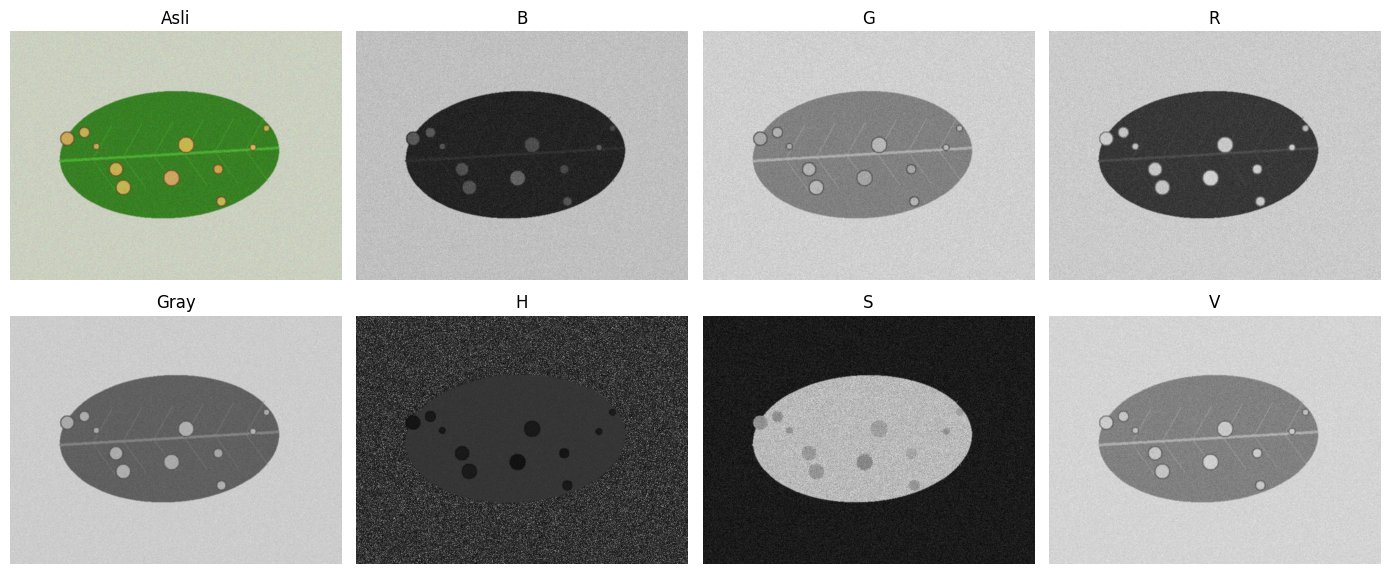

In [5]:
from utils_cv import kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")


# Kode 2.2 Sampling dan kuantisasi

fx=0.5: ukuran (240, 320), KB=6.40
fx=0.2: ukuran (96, 128), KB=5.21
fx=0.1: ukuran (48, 64), KB=3.30
fx=0.05: ukuran (24, 32), KB=1.54
k=1: 2 level, KB=5.26
k=2: 3 level, KB=5.27
k=3: 6 level, KB=2.94
k=4: 11 level, KB=4.69
k=8: 170 level, KB=5.41


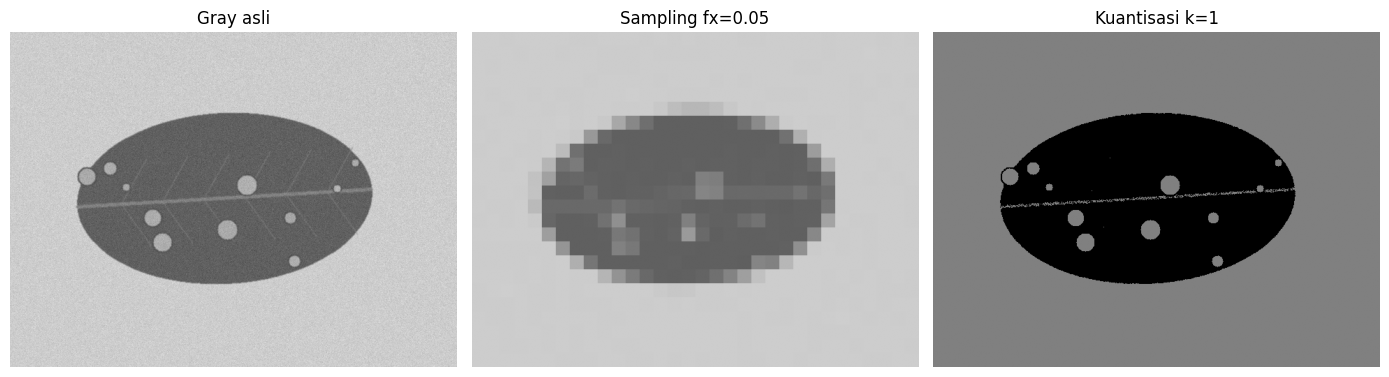

In [6]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

kecil = cv2.resize(gray, None, fx=0.05, fy=0.05, interpolation=cv2.INTER_AREA)
besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
langkah = 256 // (2 ** 1)
kuant1 = (gray // langkah) * langkah
tampil([gray, besar, kuant1],
       ["Gray asli", "Sampling fx=0.05", "Kuantisasi k=1"], ukuran=(14, 4))



# Kode 2.3 Rerata KB per kanal dan per kondisi

In [7]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")


                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.09  0.52   4.57  1.52  3.67  0.62  0.99
gelap           1.83  1.36  11.90  4.82  7.28  1.34  3.10
kontras_rendah  1.19  0.62   3.81  2.35  1.75  0.35  1.61
normal          1.71  1.07   9.35  4.57  6.94  1.12  2.54
terang          2.34  0.36   6.18  3.19  5.00  1.47  1.34


# Langkah 2.6
ulangi Kode 2.3 untuk 20 citra kelas ringan (teh_021
sampai teh_040), lalu tampilkan kanal terbaik untuk teh_021 (ringan, normal) dan teh_045
(berat, bayangan).

In [8]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")


                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.34  0.59  4.73  1.36  4.17  1.09  1.03
gelap           0.73  0.94  7.21  3.35  3.67  0.72  2.23
kontras_rendah  0.32  0.42  3.43  1.40  2.12  0.20  0.77
normal          1.70  0.83  7.67  2.30  7.75  1.34  1.32
terang          1.11  0.53  7.12  2.80  6.55  0.60  1.16


# tampilkan kanal terbaik untuk teh_021 (ringan, normal) dan teh_045 (berat, bayangan).

teh_021.png kanal terbaik: H KB=8.32
teh_045.png kanal terbaik: R KB=3.27


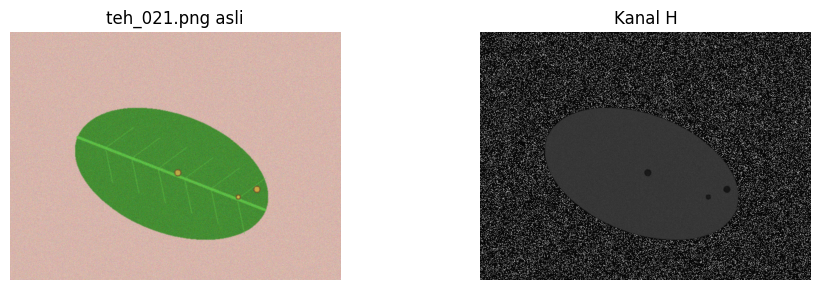

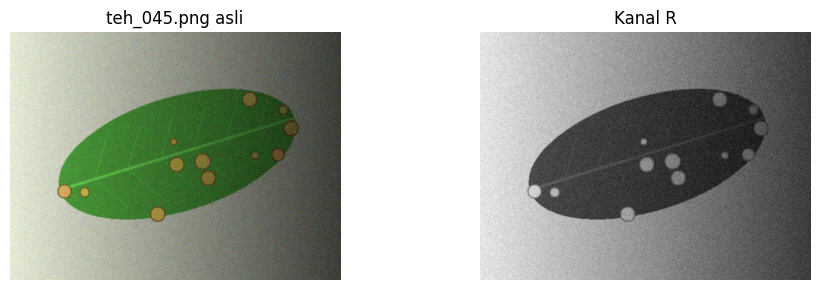

In [9]:
for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nama}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    kk = semua_kanal(im)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in kk.items()}
    terbaik = max(kb, key=kb.get)
    print(nama, "kanal terbaik:", terbaik, f"KB={kb[terbaik]:.2f}")
    tampil([im, kk[terbaik]], [f"{nama} asli", f"Kanal {terbaik}"], ukuran=(10, 3))


In [10]:
# Pemeriksaan lembar hitung 2.1 butir f memakai cv2.cvtColor
# Warna Tabel 7 ditulis dalam urutan BGR (kebalikan RGB)
bercak = np.uint8([[[86, 178, 196]]])
daun = np.uint8([[[60, 136, 52]]])
for nm, px in [("bercak", bercak), ("daun", daun)]:
    y = cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0, 0]
    hue = cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0, 0, 0]
    print(nm, "Y:", y, "Hue:", hue)


bercak Y: 173 Hue: 25
daun Y: 102 Hue: 63
